# ***CT5120: Introduction to NLP***

# ***Assignment 1: Hate Speech Classification*** (Total 100 marks)
This assignment is focused on Hate Speech Classification from social media comments.

---

###  **Student Details**

Enter your

**Name: DINESH MUTHUKUMAR**

**Student ID: 26246736**.

---

>  <font color="red">**Disclaimer:** This assignment may contain hate speech and offensive content, strictly for academic purposes. </font>

---
 **Deadline:** **`01:45 PM, 09th October, 2026`** (Ireland Time)

 **Submission Format:** `.ipynb`

 **Individual Assignment:** This is an individual assignment - your work must be your own.

<!-- ---

###  Academic Integrity

<font color="red">**Strictly no Generative AI.**</font> Do the assignment by yourself - write code and answers fully in your own words, without using AI tools.

<font color="red">**Note:**</font> You must **disable the AI features on Google Colab** before working on this assignment.
 Guide: [How to disable AI in Colab](https://youtu.be/qrGZv8nPh1o) -->



---

###  **In-Lab Grading — "Defend Your Work!**"

Think of this as a **mini viva** — you built it, so you should be able to talk through it.

| | |
|---|---|
|  **When** | `September 25th`, `October 2nd` & `October 9th, 2026` [12:00 PM to 02:00 PM] |
|  **What** | A short, friendly Q&A with your TAs |
|  **How** | TAs will ask you a few questions about your notebook |

>  **Pro tip:** You don't need to memorise every line. If you understand *What, How, & Why* you made each decision, you'll breeze through this.

No surprises, no trick questions - just show us it's genuinely **your work, and your understanding.**



---

###  **Task Roadmap**

Here's what you'll be building, step by step:

| # | Section | Focus |
|---|---|---|
| 1️ | **Dataset & EDA** | Pick a dataset, justify it, explore the classes (One example provided ) |
| 2️ | **Training & Evaluation** | Train a classifier, evaluate it properly |
| 3️ | **Improve It** | Tune the *same* model, prove it got better |

Each section builds on the last - so a solid dataset and clean features in Sections 1 will make Sections 2-3 much smoother.

---

###  Important

<!-- -  Only edit cells marked `# YOUR CODE HERE` or `# YOUR ANSWER HERE` — leave everything else untouched. -->
-  Run **all cells top-to-bottom** with no errors before submitting.
-  **Google Colab** is recommended to avoid dependency issues.

---

---
# **Dataset Details**

The dataset can be divided into **three parts**: **Training**, **Development (Dev)**, and **Test** sets.  

1. **Training set**  
   - Used to **train your model** (learn patterns from the data).  
   - This is the largest portion of the dataset.  

2. **Development (Dev) set**  
   - A small part of the training data that is **held out**.  
   - Used to **validate your model** while training and for **hyperparameter tuning**.  
   - Helps avoid overfitting (your model performing well on training but poorly on unseen data).  

3. **Test set**  
   - Contains **unlabeled data** (labels are hidden).
   - Used only for **final evaluation** of your model.  
   - You will generate a **prediction file** for this set and submit it.  

---

# Installing and Importing Packages

> **Note:** This setup cell is not directly graded. You may install and import any Python packages required for your experiments.  
> Commonly used libraries for this assignment may include `pandas`, `numpy`, `matplotlib`, `scikit-learn`, and relevant NLP libraries.

In [31]:
%pip install -q datasets pandas scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


---

# **Section 1: Dataset Selection & Exploratory Data Analysis**

### `Total = 30 marks`

Before building your classification model, select a suitable **hate-speech classification dataset** and explore its main characteristics.

> **Note:** You may use one of the example datasets provided in Task 1a, or select another appropriate publicly available dataset.

| Task | What you'll do | Marks |
|---|---|---|
| **1a** | Select and load a dataset, and prepare Train / Dev / Test splits | `5` |
| **1b** | Plot the **class distribution** using a suitable visualisation | `10` |
| **1c** | Carry out **Exploratory Data Analysis (EDA)** relevant to your dataset, such as text length, vocabulary size, common n-grams, or other informative characteristics | `5` |
| **1d** | Explain your **dataset selection** and the main findings from your EDA | `10` |

> A clear understanding of the dataset will help you make better decisions in the later modelling and evaluation sections.

---

## **1a: Dataset** (5 marks)

Select and load **one suitable hate-speech classification dataset** for this assignment.

> **Note:** You may choose **one of the example datasets listed below**, or you may use **another appropriate publicly available dataset** of your choice.

Example datasets:

1. https://huggingface.co/datasets/christinacdl/binary_hate_speech  
2. https://huggingface.co/datasets/tdavidson/hate_speech_offensive  
3. https://huggingface.co/datasets/tweets-hate-speech-detection/tweets_hate_speech_detection  
4. https://huggingface.co/datasets/badmatr11x/hate-offensive-speech  

If you choose a different dataset, it should contain:

- textual input data;
- clearly defined class labels;
- enough examples for model training and evaluation.

Use the dataset's existing **Train / Dev / Test splits** where available. If suitable splits are not provided, create them yourself.

Tutorial: [Loading a dataset from Hugging Face](https://huggingface.co/docs/datasets/load_hub)

In [32]:
from datasets import load_dataset

dataset = load_dataset("christinacdl/binary_hate_speech")


print("Available splits:", list(dataset.keys()))

for split_name, split_data in dataset.items():
    print(f"\n{split_name}: {len(split_data)} rows")
    

Available splits: ['train', 'validation', 'test']

train: 31060 rows

validation: 3883 rows

test: 3883 rows


## **1b: Class Distribution** (10 marks)

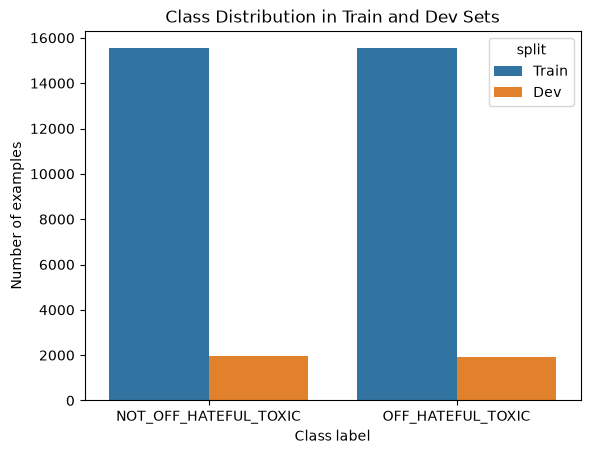

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

train_df = dataset["train"].to_pandas()
dev_df = dataset["validation"].to_pandas()

train_df["split"] = "Train"
dev_df["split"] = "Dev"

eda_df = pd.concat([train_df, dev_df], ignore_index=True)

sb.countplot(data=eda_df, x="label", hue="split")

plt.title("Class Distribution in Train and Dev Sets")
plt.xlabel("Class label")
plt.ylabel("Number of examples")
plt.show()

## **1c: Exploratory Data Analysis (EDA)** (5 marks)

Average words per comment: 19.97
Shortest comment (words): 1
Longest comment (words): 325


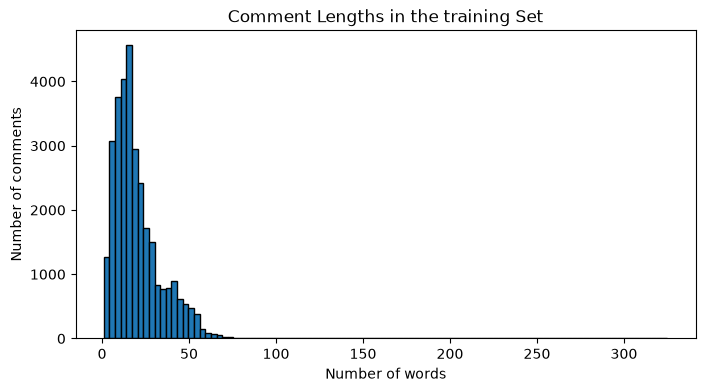

In [34]:

# Converting empty text values as an empty string to prevent errors when converting to numbers
train_texts = train_df["text"].fillna("").astype(str)

word_counts = train_texts.str.split().str.len()


print("Average words per comment:", round(word_counts.mean(), 2))
print("Shortest comment (words):", word_counts.min())
print("Longest comment (words):", word_counts.max())

plt.figure(figsize=(8, 4))
plt.hist(word_counts,bins=100,edgecolor='black')
plt.title("Comment Lengths in the training Set")
plt.xlabel("Number of words")
plt.ylabel("Number of comments")
plt.show()


## **1d: Explanation** (10 marks)

**Question:** Explain your dataset selection and your Exploratory Data Analysis (EDA) process.

Your answer should cover:
- **Why you selected this dataset?**
- **The EDA process carried out in Tasks 1a to 1c**. what you looked at (class distribution, text statistics, etc.).

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
I selected this dataset as the splits for training, dev and test were already separated. From the EDA it was found the class distribution was nearly balanced between the two classes (OFF_HATEFUL_TOXIC and NOT_OFF_HATEFUL_TOXIC) and the average comment length is around 10 - 30 words. 

```

---

#  **Section 2**: Feature Extraction, Model Training & Evaluation

### `Total = 40 marks`

Time to build your baseline model. In this section, you will convert the text into suitable numerical features or embeddings, train a classical machine-learning classifier, and evaluate its performance using appropriate metrics.

| Task   | What you'll do                                                                                                                                                            | Marks |
| ------ | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ----: |
| **2a** | Perform **feature extraction** using a suitable technique |  `10` |
| **2b** | Train a suitable **classical ML baseline classifier** using the extracted features                                                                                        |  `10` |
| **2c** | **Predict and evaluate** the model using multiple appropriate evaluation metrics                                                                                          |  `10` |
| **2d** | Explain your **feature extraction method, model choice, evaluation metrics, and results**                                                                                 |  `10` |

>  Choose a feature representation and classical machine-learning model that are suitable for your dataset. Your goal here is to establish a clear and well-evaluated **baseline model**. You will improve this same model in Section 3.

---


## **2a: Feature Extraction / Text Representation** (10 marks)
Use a suitable feature extraction or text representation technique to convert the text data into numerical features that can be used by a classical machine-learning model.

* You may use an appropriate method such as: Bag-of-Words, TF-IDF, Word2Vec, FastText or another suitable feature representation method

Your implementation should clearly show how the training, validation, and test data are transformed.

In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer

train_texts = dataset["train"]["text"]
dev_texts = dataset["validation"]["text"]
test_texts = dataset["test"]["text"]

y_train = dataset["train"]["label"]
y_dev = dataset["validation"]["label"]

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=50000,
    stop_words="english"
)

X_train = tfidf.fit_transform(train_texts)
X_dev = tfidf.transform(dev_texts)
X_test = tfidf.transform(test_texts)

print("Training feature matrix:", X_train.shape)
print("Dev feature matrix:", X_dev.shape)
print("Test feature matrix:", X_test.shape)

Training feature matrix: (31060, 50000)
Dev feature matrix: (3883, 50000)
Test feature matrix: (3883, 50000)


## **2b: Classifier Model** (10 marks)
Train a suitable classical machine-learning classifier using the features produced in Task 2a.

In [36]:
from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(max_iter=1000)
baseline_model.fit(X_train, y_train)

print("Classes learned by the model:", baseline_model.classes_)

Classes learned by the model: ['NOT_OFF_HATEFUL_TOXIC' 'OFF_HATEFUL_TOXIC']


## **2c: Predict & Evaluate** (10 marks)
Use your trained model to make predictions on the test set and evaluate its performance using multiple suitable evaluation metrics.

Dev accuracy: 0.7692505794488798

Per-class results:
                       precision    recall  f1-score   support

NOT_OFF_HATEFUL_TOXIC       0.78      0.75      0.76      1942
    OFF_HATEFUL_TOXIC       0.76      0.79      0.77      1941

             accuracy                           0.77      3883
            macro avg       0.77      0.77      0.77      3883
         weighted avg       0.77      0.77      0.77      3883



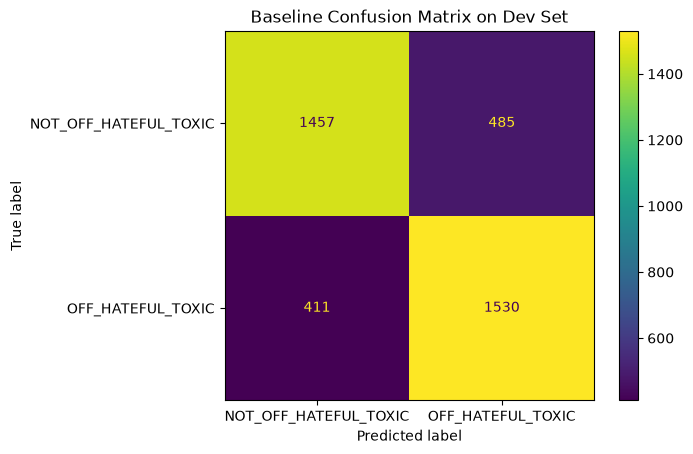

In [37]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

dev_predictions = baseline_model.predict(X_dev)

print("Dev accuracy:", accuracy_score(y_dev, dev_predictions))
print("\nPer-class results:")
print(classification_report(y_dev, dev_predictions, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_dev,
    dev_predictions,
    labels=baseline_model.classes_
)

plt.title("Baseline Confusion Matrix on Dev Set")
plt.show()

## **2d: Explanation** (10 marks)

**Question:** Explain your feature representation, baseline model choice, and evaluation results.

Your answer should cover:
* **Feature extraction** - explain which feature extraction or embedding method
you used, how it represents the text, and why it is suitable for your dataset.
* **Why you chose this classifier** - explain why the selected model is suitable for your feature representation and why it provides a reasonable baseline.
* **The metrics you reported in Task 2c** - explain what the selected metrics measure and why using only a single metric, such as accuracy, may be misleading.
* **Your results** - briefly discuss what the obtained scores indicate about the strengths and weaknesses of your baseline model.

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
Used TF-IDF because it keeps useful words and short phrases as features. 
Used logistic regression since its learned weights provide clues about which features influence its predictions. 
Using only accuracy can hide which classes the model handles poorly.
The model performs similarly on both classes: F1 is 0.76 versus 0.77.

```

---

#  **Section 3**: Improving the Model
### `Total = 30 marks`

Your model works, now make it better. The catch: you must improve the **same model** from Section 2 (e.g. SVM → tuned SVM), not swap in a different classifier.

| Task | What you'll do | Marks |
|---|---|---|
| **3a** | **Improve** your baseline (same model type) | `10` |
| **3b** | **Predict & evaluate** using multiple suitable metrics | `10` |
| **3c** | Explain your **improvement approach** and **the metrics** | `10` |

>  Use the dev set to guide your improvements - hyperparameter tuning, class-imbalance handling, or adjusting your feature-extraction parameters are all fair game.

---

## **3a: Improve your model** (10 marks)

In [38]:
from sklearn.metrics import f1_score

C_values = [0.01, 0.1, 1, 10]

best_dev_f1 = -1
best_C = None
improved_model = None

for C in C_values:
    candidate_model = LogisticRegression(
        C=C,
        max_iter=1000
    )

    candidate_model.fit(X_train, y_train)
    dev_predictions = candidate_model.predict(X_dev)
    dev_f1 = f1_score(y_dev, dev_predictions, average="macro")

    print(f"C={C}: Dev macro F1={dev_f1:.4f}")

    if dev_f1 > best_dev_f1:
        best_dev_f1 = dev_f1
        best_C = C
        improved_model = candidate_model

print(f"\nBest C: {best_C}")
print(f"Best Dev macro F1: {best_dev_f1:.4f}")

C=0.01: Dev macro F1=0.7193
C=0.1: Dev macro F1=0.7451
C=1: Dev macro F1=0.7692
C=10: Dev macro F1=0.7816

Best C: 10
Best Dev macro F1: 0.7816


## **3b: Predict & Evaluate** (10 marks)

Improved model Dev accuracy: 0.7816121555498327

Improved model per-class results:
                       precision    recall  f1-score   support

NOT_OFF_HATEFUL_TOXIC       0.79      0.77      0.78      1942
    OFF_HATEFUL_TOXIC       0.77      0.79      0.78      1941

             accuracy                           0.78      3883
            macro avg       0.78      0.78      0.78      3883
         weighted avg       0.78      0.78      0.78      3883



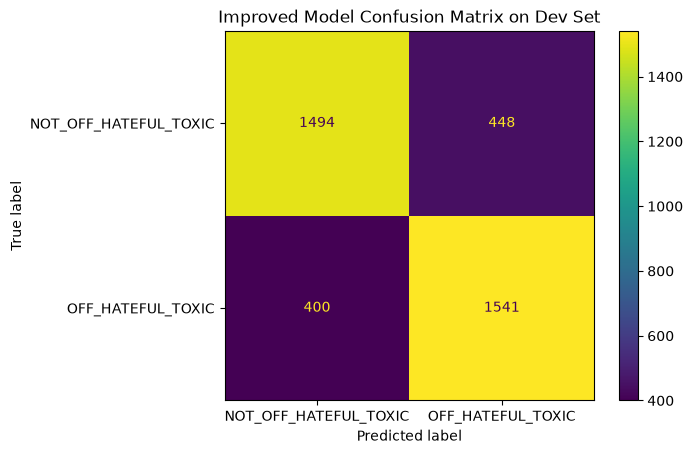

In [39]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

improved_predictions = improved_model.predict(X_dev)

print("Improved model Dev accuracy:",
      accuracy_score(y_dev, improved_predictions))

print("\nImproved model per-class results:")
print(classification_report(
    y_dev,
    improved_predictions,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_dev,
    improved_predictions,
    labels=improved_model.classes_
)

plt.title("Improved Model Confusion Matrix on Dev Set")
plt.show()

## **3c: Explanation** (10 marks)

**Question:** Explain your improvement approach and your evaluation results.

Your answer should cover:
- **What you changed and why** - the specific improvement(s) you applied in Task 3a, and why you expected them to help, based on what you observed about the baseline in Section 2.
- **The metrics you reported in Task 3b** - how they compare to your baseline's (Task 2): did your improvement actually help, on which metric(s), and by how much? If some metrics improved while others didn't, discuss why that might be.

Your explanation should be written in your own words and should not exceed **50 words** in length.

```
Baseline constraint was 1. When constraint was changed, and the larger constraint 10 was found to result in improved F1 score and improved accuracy by roughly 1.23 percentage.



```

---

#  That's a wrap!

Thanks for working through this assignment. Double-check your cells run top-to-bottom with saved outputs, then upload to `Canvas` before **01:45 PM, October 9th, 2026**.

See you at the in-lab Q&A and for the grade!

---